# Data quality assessment

How reliable, complete, and consistent is the UrbanEV dataset for exploratory analysis?

We will do 5 quality checks.

1. Missing values — Are there missing measurements across the 275 zones?

2. Zero and negative values — Are they valid observations or potential data quality issues?

3. Descriptive statistics — What are the ranges and distributions of charging measurements?

4. Outlier detection — Do we observe unusually large or suspicious values?

5. Temporal consistency — Are there unexpected gaps, sudden jumps or constant values?

We'll focus primarily on the six charging datasets, which are the core of UrbanEV.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path("data")

charging_files = [
    "volume",
    "volume-11kW",
    "duration",
    "occupancy",
    "e_price",
    "s_price"
]

# Load all six datasets into a dictionary
data = {
    name: pd.read_csv(
        DATA_DIR / f"{name}.csv",
        parse_dates=["time"]
    )
    for name in charging_files
}

print("Loaded datasets:")

for name, df in data.items():
    print(f"{name:<15} {df.shape}")


Loaded datasets:
volume          (4344, 276)
volume-11kW     (4344, 276)
duration        (4344, 276)
occupancy       (4344, 276)
e_price         (4344, 276)
s_price         (4344, 276)


### Missing value analysis

We confirmed that all six charging datasets contain 4,344 timestamps and 275 zones.

However, having all timestamps doesn't guarantee that every measurement is available.



In [2]:
missing_results = []

for name, df in data.items():

    # Exclude the timestamp column
    values = df.drop(columns=["time"])

    total_values = values.size
    missing_values = values.isna().sum().sum()

    missing_results.append({
        "dataset": name,
        "total_values": total_values,
        "missing_values": missing_values,
        "missing_pct": round(
            missing_values / total_values * 100, 4
        ),
        "zones_with_missing": (
            values.isna().sum() > 0
        ).sum()
    })

missing_summary = pd.DataFrame(missing_results)

display(missing_summary)


,dataset,total_values,missing_values,missing_pct,zones_with_missing
0,volume,1194600,0,0.0,0
1,volume-11kW,1194600,0,0.0,0
2,duration,1194600,0,0.0,0
3,occupancy,1194600,0,0.0,0
4,e_price,1194600,0,0.0,0
5,s_price,1194600,0,0.0,0


### Zero and negative values

We want to understand how often each dataset contains zeros and whether any negative measurements exist.

- Zero charging volume: Could indicate no charging activity in a zone during an hour.

- Zero charging duration: Could indicate no active charging.

- Zero occupancy: Could indicate that no charging piles were occupied.

- Zero electricity or service price: Requires closer investigation; it might indicate a valid pricing condition or a data-processing convention.

- Negative values: Would generally be unexpected for these variables and deserve investigation.

In [3]:

value_results = []

for name, df in data.items():

    values = df.drop(columns=["time"])

    total = values.size

    zero_count = (values == 0).sum().sum()
    negative_count = (values < 0).sum().sum()

    value_results.append({
        "dataset": name,
        "zero_count": zero_count,
        "zero_pct": round(zero_count / total * 100, 2),
        "negative_count": negative_count,
        "negative_pct": round(negative_count / total * 100, 2)
    })

value_summary = pd.DataFrame(value_results)

display(value_summary)


,dataset,zero_count,zero_pct,negative_count,negative_pct
0,volume,65365,5.47,0,0.0
1,volume-11kW,65169,5.46,0,0.0
2,duration,65365,5.47,0,0.0
3,occupancy,32307,2.70,0,0.0
4,e_price,0,0.00,0,0.0
5,s_price,8886,0.74,0,0.0


1. Charging volume and duration have identical zero counts.

Both contain 65,365 zero observations (5.47%). However, identical counts don't necessarily mean zeros occur at exactly the same zone-hour combinations.

2. Occupancy has fewer zero values than charging volume.

Only 2.70% of occupancy observations are zero, compared with 5.47% of charging volume observations.
This is particularly interesting because the authors distinguish between availability-based occupancy and active electricity consumption.
A charging pile may be unavailable or occupied without actively delivering electricity. Therefore, occupancy and charging volume should not necessarily be expected to match.

3. Charging prices behave differently.

Electricity prices are never zero, while service prices are zero in approximately 0.74% of observations.
These zero service prices might represent periods without an additional service fee.

4. No negative values exist.

This is encouraging because negative charging durations, consumption and prices would generally be unexpected.
One additional detail worth investigating later: volume-11kW.csv contains 196 fewer zeros than volume.csv, despite both representing estimated electricity use.

### Descriptive statistics

Now we'll examine the distributions of the measurements.
Our goal is to understand:
- What is a typical charging measurement?
- How widely do values vary?
- Are the distributions skewed?
- Are there unusually large values that deserve further investigation?

In [4]:

stats = []

for name, df in data.items():

    values = df.drop(columns=["time"]).to_numpy().ravel()

    stats.append({
        "dataset": name,
        "min": np.min(values),
        "p25": np.percentile(values, 25),
        "median": np.median(values),
        "mean": np.mean(values),
        "p75": np.percentile(values, 75),
        "p95": np.percentile(values, 95),
        "p99": np.percentile(values, 99),
        "max": np.max(values),
        "std": np.std(values)
    })

stats_summary = pd.DataFrame(stats)

display(stats_summary.round(2))


,dataset,min,p25,median,mean,p75,p95,p99,max,std
0,volume,0.00,18.67,53.67,260.88,152.54,1044.00,4465.08,16732.50,858.85
1,volume-11kW,0.00,17.50,49.00,107.69,121.00,380.92,774.00,5073.00,207.43
2,duration,0.00,2.67,7.00,13.11,16.25,48.67,78.67,207.58,17.22
3,occupancy,0.00,5.00,11.00,17.87,23.00,61.00,99.00,373.00,21.01
4,e_price,0.24,0.82,0.96,0.95,1.06,1.22,1.50,1.80,0.19
5,s_price,0.00,0.71,0.76,0.72,0.76,0.85,1.00,1.45,0.13


1. Charging volume is strongly right-skewed

Median charging volume = 53.67 kWh

Mean charging volume = 260.88 kWh


The mean is almost five times the median (a heavily right-skewed distribution).
The 99th percentile is 4,465.08 kWh, and the maximum reaches 16,732.50 kWh.
Thus, a relatively small number of zone-hour observations have much greater estimated charging volume than typical observations.
Importantly, these are aggregated zone-level measurements, not individual vehicle charging sessions. We shouldn't label the maximum an outlier without considering the number and rated power of charging piles in the zone.

2. The two charging-volume estimates differ substantially

The average estimated charging volume is:

- `volume.csv`: 260.88 kWh
- `volume-11kW.csv`: 107.69 kWh

The rated-power estimate is approximately 2.42 times higher on average.

The choice of estimation method substantially affects reported electricity consumption.

The authors provide the alternative 11 kW estimate to address potential overestimation caused by using charging-pile rated power.

3. Charging duration is also right-skewed

The median charging duration is 7 hours, while the mean is 13.11 hours.
The maximum reaches 207.58 hours.

4. Occupancy deserves special attention

The maximum occupancy is 373, which is greater than 100.

The current `occupancy.csv` probably contains counts of occupied charging piles rather than percentages. The repository's description and dataset-version changes warrant particular care here.

5. Charging prices have narrower distributions

Electricity prices range from 0.24 to 1.80 yuan/kWh, with a median of 0.96 yuan/kWh.
Service prices range from 0 to 1.45 yuan/kWh, with a median of 0.76 yuan/kWh.
They are considerably less skewed than charging volume or duration.

### Validate occupancy against charging capacity

If occupancy represents the number of occupied charging piles, it should generally not exceed the number of available piles in the corresponding zone.

We already know from Notebook 01 that the largest zone contains 373 charging piles — coincidentally, the same number as the maximum occupancy observed.

If occupancy represents the number of occupied charging piles, the ratio

$$
\text{Occupancy ratio} =
\frac{\text{Occupied charging piles}}{\text{Total charging piles in zone}}
$$

should generally fall between 0 and 1.

In [5]:

# Load station information
stations = pd.read_csv(DATA_DIR / "inf.csv")

# Calculate charging pile capacity per zone
zone_capacity = (
    stations.groupby("TAZID")["charge_count"].sum()
)

# Extract occupancy measurements
occupancy = data["occupancy"].drop(columns=["time"]).copy()

# Convert column names to integer zone IDs
occupancy.columns = occupancy.columns.astype(int)

# Align capacity with occupancy columns
capacity = zone_capacity.reindex(occupancy.columns)

# Check for occupancy exceeding available charging piles
exceeds_capacity = occupancy.gt(capacity, axis=1)

print("Zone-hour observations:", occupancy.size)

print(
    "Observations exceeding zone capacity:",
    exceeds_capacity.to_numpy().sum()
)

print(
    "Zones with capacity violations:",
    exceeds_capacity.any(axis=0).sum()
)

# Calculate occupancy relative to zone capacity
occupancy_ratio = occupancy.div(capacity, axis=1)

print("\nOccupancy / capacity ratio:")
display(
    occupancy_ratio.stack().describe(
        percentiles=[0.5, 0.95, 0.99]
    ).round(3)
)


Zone-hour observations: 1194600
Observations exceeding zone capacity: 0
Zones with capacity violations: 0

Occupancy / capacity ratio:


count    1194600.000
mean           0.271
std            0.180
min            0.000
50%            0.235
95%            0.625
99%            0.889
max            1.000
dtype: float64

1. Occupancy never exceeds charging capacity.

Across all 1,194,600 zone-hour observations, the number of occupied charging piles never exceeds the total number of charging piles in the corresponding zone.
This strongly supports our interpretation that occupancy.csv contains counts of occupied or unavailable charging piles rather than percentages.

2. Occupancy is relatively low on average.

The mean occupancy ratio is 27.1%, while the median is 23.5%.
These percentages are calculated by giving each zone-hour equal weight. They do not represent the percentage of all charging piles in Shenzhen that are occupied at any given moment.

3. High occupancy is relatively uncommon.

Most zone-hour observations have substantial unoccupied charging capacity, although individual zones can become fully occupied.
The authors define occupancy from an availability perspective. An occupied or unavailable pile isn't necessarily delivering electricity.


### Investigating potential outliers

Now we examine the extreme charging-volume values we observed earlier.

Recall that volume.csv has:
- Median: 53.67 kWh
- Mean: 260.88 kWh
- 99th percentile: 4,465.08 kWh
- Maximum: 16,732.50 kWh

The distribution is strongly right-skewed.
However, there is an important methodological consideration.
We should detect unusually high values within individual zones, rather than compare every zone against one global threshold.
Why? A zone with 300 charging piles can naturally have much higher electricity consumption than a zone with just 10 piles.

We'll use the Interquartile Range (IQR) method separately for each zone.

$$
IQR = Q_{75} - Q_{25}
$$

An observation will be flagged when:

$$
Volume > Q_{75} + 1.5 \times IQR
$$

In [ ]:
# Extract charging volume measurements
vol = data["volume"].drop(columns=["time"])

# Calculate IQR thresholds separately for each zone
q1 = vol.quantile(0.25)
q3 = vol.quantile(0.75)

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

# Flag unusually high observations
outliers = vol.gt(upper_bound, axis=1)

# Summarize potential outliers
outlier_summary = pd.DataFrame({
    "zone": vol.columns,
    "outlier_count": outliers.sum().values,
    "outlier_pct": (outliers.mean() * 100).values,
    "max_volume": vol.max().values,
    "upper_bound": upper_bound.values
})

print("Total observations:", vol.size)
print("Potential high outliers:", outliers.sum().sum())

print(
    "Percentage flagged:",
    round(outliers.to_numpy().mean() * 100, 2),
    "%"
)

print(
    "Zones with flagged observations:",
    outliers.any(axis=0).sum()
)

print("\nTop 10 zones by percentage flagged:")
display(
    outlier_summary
    .sort_values("outlier_pct", ascending=False)
    .head(10)
    .round(2)
)


Total observations: 1194600
Potential high outliers: 11802
Percentage flagged: 0.99 %
Zones with flagged observations: 186

Top 10 zones by percentage flagged:


,zone,outlier_count,outlier_pct,max_volume,upper_bound
88,592,490,11.28,9432.50,5770.62
160,848,369,8.49,70.00,40.54
104,655,362,8.33,77.00,42.88
175,895,362,8.33,6420.00,3533.75
49,343,359,8.26,162.17,86.04
95,631,358,8.24,321.00,168.17
35,321,328,7.55,147.00,81.38
15,206,316,7.27,322.29,232.64
34,320,294,6.77,58.04,33.25
97,633,235,5.41,10212.50,7444.07


1. Most observations are not flagged as unusually high.

Only 0.99% of the 1,194,600 zone-hour observations exceed their respective zone's IQR upper threshold.

2. Potential outliers are unevenly distributed across zones.

Of the 275 zones, 186 contain at least one flagged observation, while 89 contain none.
Zone 592 stands out with 490 flagged observations, representing 11.28% of its hourly measurements.
Zone 848 follows with 369 flagged observations (8.49%).

3. An unusually high value depends on the zone.
Consider these two examples:

Zone	Maximum volume	IQR upper threshold

| Zone ID | Max volume | IQR upper threshold |
|---------|--------------|----------------|
| 592     | 9,432.50 kWh | 5,770.62 kWh   |
| 848     | 70.00 kWh    | 40.54 kWh      |

A measurement of 70 kWh is considered unusually high in zone 848, whereas much larger measurements are typical in zone 592.

### Are potential outliers concentrated at certain hours?

Now we investigate the temporal distribution of the flagged observations.
For example, suppose most unusually high charging-volume observations occur during the afternoon or evening. That could suggest these values are related to regular charging behavior rather than random measurement errors.

,flagged_count,n_timestamps,flagged_pct
hour,,,
0,780,181,1.57
1,830,181,1.67
2,485,181,0.97
3,417,181,0.84
4,406,181,0.82
5,370,181,0.74
6,393,181,0.79
7,402,181,0.81
8,247,181,0.50


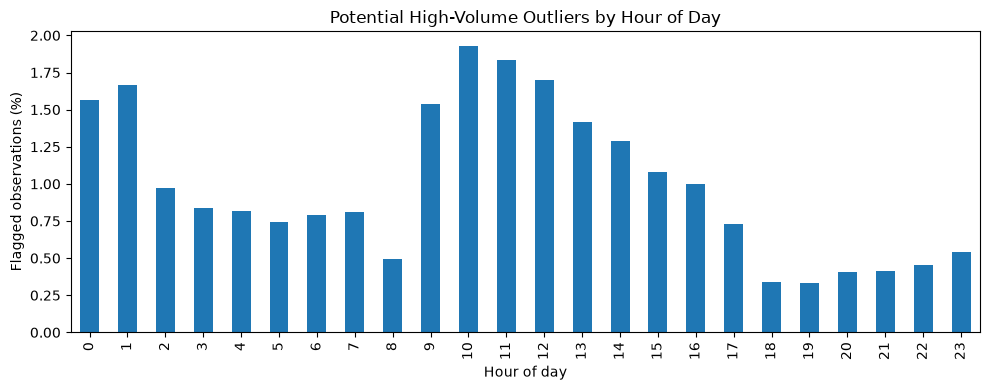

In [7]:
import matplotlib.pyplot as plt

# Count flagged zones at each timestamp
temporal_outliers = pd.DataFrame({
    "time": data["volume"]["time"],
    "flagged_zones": outliers.sum(axis=1)
})

# Extract hour of day
temporal_outliers["hour"] = temporal_outliers["time"].dt.hour

# Aggregate by hour
hourly_outliers = (
    temporal_outliers
    .groupby("hour")
    .agg(
        flagged_count=("flagged_zones", "sum"),
        n_timestamps=("time", "count")
    )
)

# Percentage of zone-hour observations flagged
hourly_outliers["flagged_pct"] = (
    hourly_outliers["flagged_count"]
    / (hourly_outliers["n_timestamps"] * vol.shape[1])
    * 100
)

display(hourly_outliers.round(2))

# Visualize
ax = hourly_outliers["flagged_pct"].plot(
    kind="bar",
    figsize=(10, 4)
)

ax.set_title("Potential High-Volume Outliers by Hour of Day")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Flagged observations (%)")

plt.tight_layout()
plt.show()


The potential outliers are not uniformly distributed throughout the day. There is a clear relationship between the hour of day and how frequently high charging-volume observations are flagged.

The chart shows when outlier flags occur most frequently, not necessarily when total charging demand is highest.

1. Potential outliers peak during the late morning.

The highest concentration occurs between 09:00 and 12:00, with another notable peak at 00:00–01:00.
In contrast, the evening hours (18:00–23:00) have relatively few flagged observations.

2. The difference is substantial.

At 10:00, the flag rate is approximately 5.8 times higher than at 19:00.
Since we have exactly 181 observations for every hour in each zone, this difference cannot be explained by unequal sample sizes.

3. Regular charging patterns might be contributing to the flags.

Our IQR calculation uses one upper threshold per zone, regardless of the hour.
But what if a particular zone consistently experiences higher charging volumes at 10:00 than at 19:00?
Those regular morning peaks could repeatedly exceed the zone's overall IQR threshold, even though they represent normal charging behavior.

### Account for hourly patterns in outlier detection

We calculate IQR thresholds separately for each combination of zone and hour of day.

Instead of comparing Monday at 10:00 against every observation in that zone, we'll compare it against the other 10:00 observations in the same zone.

This should help us determine whether the flags are partly explained by regular daily patterns.

In [8]:
# Charging volume with datetime index
vol_hourly = data["volume"].set_index("time")

# Compute quartiles for each zone and hour of day
hourly_q1 = vol_hourly.groupby(
    vol_hourly.index.hour
).quantile(0.25)

hourly_q3 = vol_hourly.groupby(
    vol_hourly.index.hour
).quantile(0.75)

# Hour-specific upper thresholds
hourly_upper = hourly_q3 + 1.5 * (hourly_q3 - hourly_q1)

# Match the appropriate hourly threshold to each timestamp
upper_per_timestamp = hourly_upper.loc[vol_hourly.index.hour]
upper_per_timestamp.index = vol_hourly.index

# Detect unusually high observations
hour_aware_outliers = vol_hourly.gt(upper_per_timestamp)

# Compare against our original method
original_outliers = outliers.copy()
original_outliers.index = vol_hourly.index

print("Original IQR flags:",
      original_outliers.to_numpy().sum())

print("Hour-aware IQR flags:",
      hour_aware_outliers.to_numpy().sum())

print("\nPercentage flagged:")
print(
    "Original:",
    round(original_outliers.to_numpy().mean() * 100, 2),
    "%"
)
print(
    "Hour-aware:",
    round(hour_aware_outliers.to_numpy().mean() * 100, 2),
    "%"
)

# Compare hourly distributions
comparison = pd.DataFrame({
    "original_pct": (
        original_outliers.groupby(
            original_outliers.index.hour
        ).mean().mean(axis=1) * 100
    ),
    "hour_aware_pct": (
        hour_aware_outliers.groupby(
            hour_aware_outliers.index.hour
        ).mean().mean(axis=1) * 100
    )
})

display(comparison.round(2))


Original IQR flags: 11802
Hour-aware IQR flags: 13237

Percentage flagged:
Original: 0.99 %
Hour-aware: 1.11 %


,original_pct,hour_aware_pct
time,,
0,1.57,0.85
1,1.67,0.87
2,0.97,0.88
3,0.84,1.03
4,0.82,1.03
5,0.74,0.96
6,0.79,1.07
7,0.81,1.10
8,0.50,1.22


1. Accounting for time of day did not reduce the total number of flags.

The hour-aware method identified 1,435 more observations than the original method.


2. The hourly distribution became much more balanced.

Previously, the flag rate ranged from 0.33% at 19:00 to 1.93% at 10:00.
With hour-aware IQR, the rates range from approximately 0.85% to 1.36%.
Thus, the regular daily charging patterns contributed to the uneven distribution of flags under the original method.

3. Neither method establishes which observations are incorrect.

The original method identifies observations that are unusually high relative to a zone's overall distribution.

The hour-aware method identifies observations unusually high relative to the same zone at the same hour of day.

**We should keep the original measurements unchanged and document our findings rather than remove statistical outliers.**

### Temporal consistency and repeated values

We've already confirmed that the dataset has no missing timestamps.

Now let's look for another potential preprocessing artifact: consecutive identical measurements.

The authors explain that missing observations were sometimes filled using neighboring values. This can create repeated measurements over time.

However, repeated values can also occur naturally, especially when charging activity is stable.

We'll concentrate on `volume.csv` and distinguish between repeated zeros and repeated positive values.

In [9]:
vol = data["volume"].drop(columns=["time"])

# Compare each observation with the previous hour
previous = vol.shift(1)

# Consecutive identical positive values
repeated_positive = vol.eq(previous) & vol.gt(0)

# Consecutive zeros
repeated_zero = vol.eq(0) & previous.eq(0)

total_transitions = (len(vol) - 1) * vol.shape[1]

print("Total consecutive zone-hour pairs:", total_transitions)

print("\nRepeated positive values:")
print("Count:", repeated_positive.sum().sum())
print(
    "Percentage:",
    round(repeated_positive.to_numpy().sum()
          / total_transitions * 100, 2),
    "%"
)

print("\nConsecutive zeros:")
print("Count:", repeated_zero.sum().sum())
print(
    "Percentage:",
    round(repeated_zero.to_numpy().sum()
          / total_transitions * 100, 2),
    "%"
)

# Longest sequence of identical positive values per zone
longest_runs = {}

for zone in vol.columns:
    series = vol[zone]

    # Identify runs of consecutive identical values
    run_id = series.ne(series.shift()).cumsum()

    run_lengths = series.groupby(run_id).size()
    run_values = series.groupby(run_id).first()

    positive_runs = run_lengths[run_values > 0]

    longest_runs[zone] = (
        int(positive_runs.max())
        if not positive_runs.empty else 0
    )

longest_runs = pd.Series(
    longest_runs,
    name="longest_positive_run"
)

print("\nLongest positive constant sequence (hours):")
print(longest_runs.max())

print("\nZones with sequences of 6+ identical positive hours:")
print((longest_runs >= 6).sum())

print("\nTop 10 zones by longest sequence:")
display(
    longest_runs.sort_values(ascending=False)
    .head(10)
    .to_frame()
)


Total consecutive zone-hour pairs: 1194325

Repeated positive values:
Count: 323295
Percentage: 27.07 %

Consecutive zeros:
Count: 58930
Percentage: 4.93 %

Longest positive constant sequence (hours):
275

Zones with sequences of 6+ identical positive hours:
268

Top 10 zones by longest sequence:


,longest_positive_run
718,275
1060,239
1099,239
214,239
1112,239
987,239
883,239
322,239
321,239
979,239


1. More than one-quarter of consecutive zone-hour pairs have exactly the same positive charging volume.

Repeated values may arise naturally because of stable charging activity, the way electricity consumption is estimated, or preprocessing.

2. Some constant sequences are surprisingly long.

Zone 718 contains a sequence of 275 consecutive hours with exactly the same positive charging volume.
Several other zones contain sequences lasting exactly 239 hours.
The repeated 239-hour run length across multiple zones could indicate a shared period affected by preprocessing.

3. This doesn't establish that the data is incorrect.

The authors describe missing-value imputation in their preprocessing pipeline. Long constant sequences could be related to that process,

### Cross-variable consistency

We now investigate whether the charging variables behave consistently with each other.
In particular, we want to answer two questions:
1. Do charging volume and charging duration become zero at the same zone-hours?
2. Does the unusually long constant sequence in zone 718 also appear in the other charging measurements?

In [10]:

# Prepare aligned time series
v = data["volume"].set_index("time")
v11 = data["volume-11kW"].set_index("time")
d = data["duration"].set_index("time")
o = data["occupancy"].set_index("time")

# Compare zero-value patterns
checks = {
    "Volume = 0, duration > 0":
        ((v == 0) & (d > 0)).to_numpy().sum(),

    "Volume > 0, duration = 0":
        ((v > 0) & (d == 0)).to_numpy().sum(),

    "Volume = 0, 11kW volume > 0":
        ((v == 0) & (v11 > 0)).to_numpy().sum(),

    "Volume > 0, 11kW volume = 0":
        ((v > 0) & (v11 == 0)).to_numpy().sum(),

    "Volume = 0, occupancy > 0":
        ((v == 0) & (o > 0)).to_numpy().sum(),

    "Volume > 0, occupancy = 0":
        ((v > 0) & (o == 0)).to_numpy().sum()
}

display(
    pd.DataFrame(
        checks.items(),
        columns=["condition", "observations"]
    )
)

# Investigate the longest constant sequence
zone = "718"
series = v[zone]

run_id = series.ne(series.shift()).cumsum()

runs = (
    pd.DataFrame({
        "time": series.index,
        "value": series.to_numpy(),
        "run": run_id.to_numpy()
    })
    .groupby("run")
    .agg(
        start=("time", "first"),
        end=("time", "last"),
        hours=("time", "size"),
        volume_kwh=("value", "first")
    )
)

longest = (
    runs[runs["volume_kwh"] > 0]
    .sort_values("hours", ascending=False)
    .head(1)
)

print("\nLongest positive constant sequence in zone 718:")
display(longest)

start = longest.iloc[0]["start"]
end = longest.iloc[0]["end"]

print("\nDistinct values during that period:")
print("Volume:", v.loc[start:end, zone].nunique())
print("Duration:", d.loc[start:end, zone].nunique())
print("11kW volume:", v11.loc[start:end, zone].nunique())
print("Occupancy:", o.loc[start:end, zone].nunique())


,condition,observations
0,"Volume = 0, duration > 0",0
1,"Volume > 0, duration = 0",0
2,"Volume = 0, 11kW volume > 0",205
3,"Volume > 0, 11kW volume = 0",9
4,"Volume = 0, occupancy > 0",37717
5,"Volume > 0, occupancy = 0",4659



Longest positive constant sequence in zone 718:


,start,end,hours,volume_kwh
run,,,,
1259,2023-01-22 01:00:00,2023-02-02 11:00:00,275,7.0



Distinct values during that period:
Volume: 1
Duration: 1
11kW volume: 1
Occupancy: 1


1. Charging volume and duration are perfectly consistent at zero

Across all 1,194,600 zone-hour observations, charging volume is zero exactly when charging duration is zero.
This is consistent with the authors' methodology for estimating electricity consumption from charging activity and rated power.

2. The alternative 11 kW estimate has some differences

There are 205 observations where the original volume is zero but the 11 kW estimate is positive, and 9 observations with the opposite pattern.
That's only 214 observations in total, so the zero/nonzero patterns are almost identical.
Nevertheless, this shows that the two volume estimates are not interchangeable.

3. Occupancy and charging volume don't always agree

Occupied, but zero charging volume = 37,717

Charging volume positive, occupancy zero = 4,659

The first case is consistent with the distinction between charging-pile availability and active electricity delivery.
The second case is more surprising. Positive charging volume with zero recorded occupancy may reflect different aggregation rules, measurement timing or preprocessing.

### Final Data Quality Summary


## Data Quality Assessment — Key Findings

We assessed six hourly charging datasets containing
1,194,600 zone-hour observations each.

### 1. Completeness

- No missing values across the six datasets.
- No missing or duplicated hourly timestamps.
- All six datasets share the same spatial and temporal structure.

The dataset is structurally complete, although missing
measurements may have been filled during preprocessing.

### 2. Zero and negative values

- Zero charging volume: 5.47%
- Zero charging duration: 5.47%
- Zero occupancy: 2.70%
- Zero electricity prices: 0%
- Zero service prices: 0.74%
- No negative measurements were detected.

Zero values are not necessarily data quality errors.

### 3. Statistical distributions

Charging volume is strongly right-skewed.

- Median volume: 53.67 kWh per zone-hour
- Mean volume: 260.88 kWh per zone-hour
- Maximum volume: 16,732.50 kWh per zone-hour

The alternative 11 kW estimation produces substantially
lower mean charging volumes (107.69 kWh).

These estimates should not be interpreted as directly
metered electricity consumption.

### 4. Occupancy consistency

- No occupancy measurements exceed zone charging capacity.
- Mean zone-hour occupancy ratio: 27.1%
- Median zone-hour occupancy ratio: 23.5%

The measurements are consistent with occupancy representing
counts of unavailable or occupied charging piles.

### 5. Statistical outliers

- Zone-specific IQR: 0.99% flagged
- Zone-and-hour-specific IQR: 1.11% flagged

The hour-aware approach produces a more balanced
distribution of flags throughout the day.

Statistical outliers are not necessarily invalid observations.
No outliers were removed.

### 6. Temporal consistency

- 27.07% of consecutive zone-hour pairs have identical
  positive charging volume.
- 4.93% have consecutive zero volume.
- 268 of 275 zones have positive constant sequences
  lasting at least six hours.
- The longest positive constant sequence lasts 275 hours.

In zone 718, volume, alternative volume, duration and
occupancy remain constant over the same 275-hour period.

These patterns may reflect stable activity, the estimation
methodology or preprocessing effects.

### 7. Cross-variable consistency

- Charging volume and duration have identical zero patterns.
- The two volume estimates differ in their zero patterns
  for 214 zone-hour observations.
- Occupancy and charging volume can differ because they
  represent distinct aspects of charging activity.
- In 4,659 observations, positive charging volume coincides
  with zero recorded occupancy.

These discrepancies deserve consideration when interpreting
relationships between variables.

## Overall assessment

UrbanEV provides a structurally complete and internally
well-aligned dataset suitable for exploratory analysis.

However, several important limitations remain:

1. Electricity consumption is estimated.
2. The data has already undergone filtering and imputation.
3. Some measurements exhibit unusually long constant sequences.
4. Occupancy and active charging volume are not equivalent.
5. Statistical outlier flags should not automatically
   be interpreted as measurement errors.

For subsequent exploratory analysis, we retain the original
measurements and document these limitations explicitly.
